In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('/home/lactea/Documentos/data_science_projects/tech_challenge/desafio_nps_fase_1.csv')

In [3]:
df.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2500 non-null   int64  
 1   customer_age               2500 non-null   int64  
 2   customer_region            2500 non-null   str    
 3   customer_tenure_months     2500 non-null   int64  
 4   order_id                   2500 non-null   int64  
 5   order_value                2500 non-null   float64
 6   items_quantity             2500 non-null   int64  
 7   discount_value             2500 non-null   float64
 8   payment_installments       2500 non-null   int64  
 9   delivery_time_days         2500 non-null   int64  
 10  delivery_delay_days        2500 non-null   int64  
 11  freight_value              2500 non-null   float64
 12  delivery_attempts          2500 non-null   int64  
 13  customer_service_contacts  2500 non-null   int64  
 14  res

In [5]:
colunas = {
    'customer_id':'id_cliente',
    'order_id':'id_pedido',
    'customer_age': 'idade_cliente',
    'customer_region': 'regiao_cliente',
    'customer_tenure_months': 'tempo_relacionamento_cliente_empresa_meses',
    'order_value': 'valor_pedido',
    'items_quantity': 'quantidade_itens_pedido',
    'discount_value': 'desconto_aplicado_pedido',
    'payment_installments': 'numero_parcelas_pagamento',
    'delivery_time_days': 'tempo_total_entrega_dias',
    'delivery_delay_days': 'tempo_atraso_entrega_dias',
    'freight_value': 'valor_frete',
    'delivery_attempts': 'numero_tentativas_entrega',
    'customer_service_contacts': 'numero_contatos_do_cliente_e_atendimento',
    'resolution_time_days': 'tempo_resolucao_problemas_dias',
    'complaints_count': 'numero_reclamacoes_registradas_cliente',
    'repeat_purchase_30d': 'recompra_em_ate_30d',
    'csat_internal_score': 'score_interno_satisfacao_cliente',
    'nps_score': 'pontuacao_nps'
}

df.rename(columns=colunas, inplace=True)
df.head()

/tmp/ipykernel_8332/3485235937.py:23: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns=colunas, inplace=True)


,id_cliente,idade_cliente,regiao_cliente,tempo_relacionamento_cliente_empresa_meses,id_pedido,valor_pedido,quantidade_itens_pedido,desconto_aplicado_pedido,numero_parcelas_pagamento,tempo_total_entrega_dias,tempo_atraso_entrega_dias,valor_frete,numero_tentativas_entrega,numero_contatos_do_cliente_e_atendimento,tempo_resolucao_problemas_dias,pontuacao_nps,recompra_em_ate_30d,numero_reclamacoes_registradas_cliente,score_interno_satisfacao_cliente
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [6]:
df['id_cliente'].nunique()

2500

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.shape

(2500, 19)

In [9]:
import matplotlib.pyplot as plt
import numpy as np

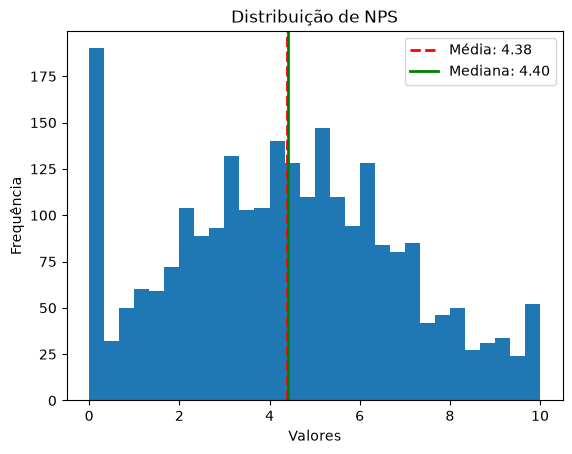

In [10]:
media = np.mean(df['pontuacao_nps'])
mediana = np.median(df['pontuacao_nps'])

plt.hist(df['pontuacao_nps'], bins=30)
plt.title('Distribuição de NPS')
plt.xlabel('Valores')
plt.ylabel('Frequência')

plt.axvline(media, color='red', linestyle='--',
            linewidth=2, label=f'Média: {media:.2f}')

plt.axvline(mediana, color='green', linestyle='-', linewidth=2, label=f'Mediana: {mediana:.2f}')

plt.legend()
plt.show()

In [11]:
media = df['pontuacao_nps'].mean()
mediana = df['pontuacao_nps'].median()
moda = df['pontuacao_nps'].mode()
desvio_padrao = df['pontuacao_nps'].std()

print(f'Média: {media:.2f}')
print(f'Mediana: {mediana:.2f}')
print(f'Moda: {moda}')
print(f'Desvio Padrão: {desvio_padrao:.2f}')

Média: 4.38
Mediana: 4.40
Moda: 0    0.0
Name: pontuacao_nps, dtype: float64
Desvio Padrão: 2.51


In [12]:
df['pontuacao_nps'].value_counts()

pontuacao_nps
0.0    158
4.5     49
4.9     44
3.9     44
3.4     42
      ... 
9.3      6
9.0      5
9.8      4
9.9      3
9.7      3
Name: count, Length: 101, dtype: int64

In [76]:
quantidade_total_de_pedidos = len(df)

In [79]:
qtd_pontuacao_nps_0 = len(df[df['pontuacao_nps'] == 0.0])
qtd_pontuacao_nps_menor_igual_5 = len(df[df['pontuacao_nps'] <= 5])
print(qtd_pontuacao_nps_0)
print(qtd_pontuacao_nps_menor_igual_5)

158
1507


In [80]:
porcentagem_pontuacao_nps_0 = (qtd_pontuacao_nps_0/quantidade_total_de_pedidos) * 100
porcentagem_pontuacao_nps_menor_igual_5 = (qtd_pontuacao_nps_menor_igual_5/quantidade_total_de_pedidos) * 100
print(f'Porcentagem de NPS Score 0: {porcentagem_pontuacao_nps_0:.2f}%')
print(f'Porcentagem de NPS Score menor ou igual a 5: {porcentagem_pontuacao_nps_menor_igual_5:.2f}%')

Porcentagem de NPS Score 0: 6.32%
Porcentagem de NPS Score menor ou igual a 5: 60.28%


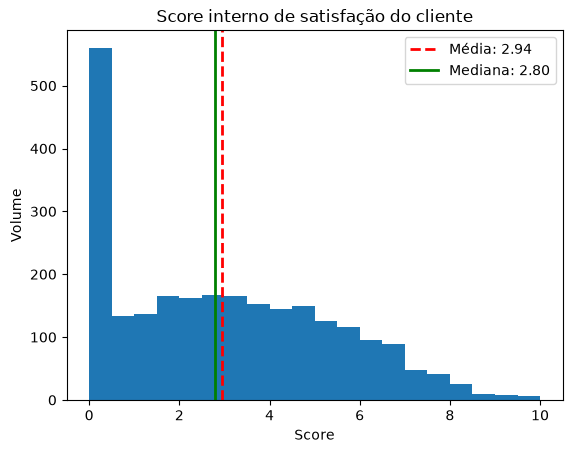

In [13]:
media = df['score_interno_satisfacao_cliente'].mean()
mediana = df['score_interno_satisfacao_cliente'].median()

plt.hist(df['score_interno_satisfacao_cliente'], bins=20)
plt.title('Score interno de satisfação do cliente')
plt.xlabel('Score')
plt.ylabel('Volume')
plt.axvline(media, color='red', linestyle='--', linewidth=2, label=f'Média: {media:.2f}')
plt.axvline(mediana, color='green', linestyle='-', linewidth=2, label=f'Mediana: {mediana:.2f}')

plt.legend()
plt.show()

In [14]:
df['score_interno_satisfacao_cliente'].value_counts()

score_interno_satisfacao_cliente
0.0    462
1.7     42
4.0     41
2.4     40
4.9     40
      ... 
8.5      1
9.9      1
9.5      1
8.9      1
9.6      1
Name: count, Length: 98, dtype: int64

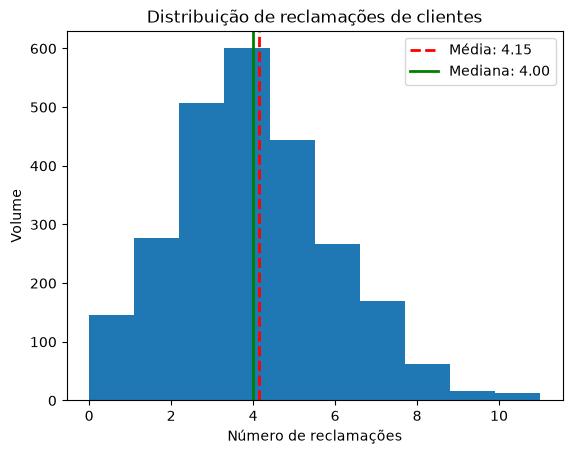

In [15]:
media = df['numero_reclamacoes_registradas_cliente'].mean()
mediana = df['numero_reclamacoes_registradas_cliente'].median()

plt.hist(df['numero_reclamacoes_registradas_cliente'], bins=10)
plt.title('Distribuição de reclamações de clientes')
plt.xlabel('Número de reclamações')
plt.ylabel('Volume')
plt.axvline(media, color='red', linestyle='--', linewidth=2, label=f'Média: {media:.2f}')
plt.axvline(mediana, color='green', linestyle='-', linewidth=2, label=f'Mediana: {mediana:.2f}')

plt.legend()
plt.show()

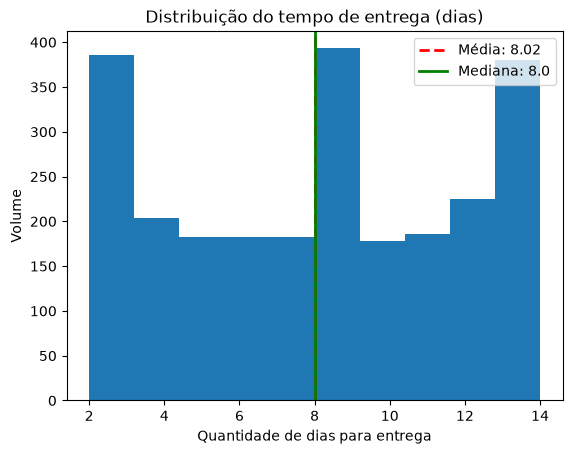

In [16]:
media = df['tempo_total_entrega_dias'].mean()
mediana = df['tempo_total_entrega_dias'].median()

plt.hist(df['tempo_total_entrega_dias'], bins=10)
plt.title('Distribuição do tempo de entrega (dias)')
plt.xlabel('Quantidade de dias para entrega')
plt.ylabel('Volume')
plt.axvline(media, color='red', linestyle='--', linewidth=2, label=f'Média: {media:.2f}')
plt.axvline(mediana, color='green', linestyle='-', linewidth=2, label=f'Mediana: {mediana:.2}')

plt.legend()
plt.show()

In [17]:
media_por_regiao = df.groupby('regiao_cliente')['tempo_total_entrega_dias'].mean() 
mediana_por_regiao = df.groupby('regiao_cliente')['tempo_total_entrega_dias'].median()

media_por_regiao

regiao_cliente
Centro-Oeste    7.912393
Nordeste        8.160825
Norte           7.758893
Sudeste         8.201923
Sul             8.067179
Name: tempo_total_entrega_dias, dtype: float64

In [18]:
mediana_por_regiao

regiao_cliente
Centro-Oeste    8.0
Nordeste        8.0
Norte           8.0
Sudeste         8.0
Sul             8.0
Name: tempo_total_entrega_dias, dtype: float64

In [19]:
df['tempo_total_entrega_dias'].value_counts()

tempo_total_entrega_dias
12    225
4     204
2     203
8     202
14    195
9     191
11    186
13    185
5     183
7     183
3     183
6     182
10    178
Name: count, dtype: int64

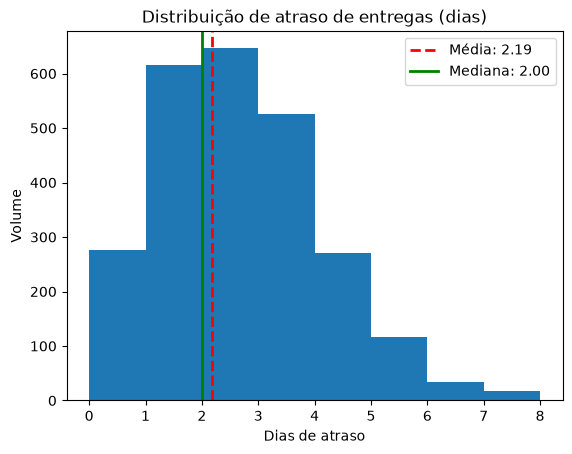

In [20]:
media = df['tempo_atraso_entrega_dias'].mean()
mediana = df['tempo_atraso_entrega_dias'].median()

plt.hist(df['tempo_atraso_entrega_dias'], bins=8)
plt.title('Distribuição de atraso de entregas (dias)')
plt.xlabel('Dias de atraso')
plt.ylabel('Volume')
plt.axvline(media, color='red', linestyle='--', linewidth=2, label=f'Média: {media:.2f}')
plt.axvline(mediana, color='green', linestyle='-', linewidth=2, label=f'Mediana: {mediana:.2f}')

plt.legend()
plt.show()

In [21]:
df['tempo_atraso_entrega_dias'].value_counts()

tempo_atraso_entrega_dias
2    646
1    615
3    525
0    277
4    270
5    116
6     34
7     14
8      3
Name: count, dtype: int64

In [22]:
atrasados = df[df['tempo_atraso_entrega_dias'] != 0]
num_atrasados = atrasados.value_counts().sum()

In [23]:
entregue_no_prazo = df[df['tempo_atraso_entrega_dias'] == 0]
num_entregues_prazo = entregue_no_prazo.value_counts().sum()

In [25]:
porcentagem_de_pedidos_atrasados = (num_atrasados / quantidade_total_de_pedidos) * 100
porcentagem_sem_atraso = (num_entregues_prazo / quantidade_total_de_pedidos) * 100

print('-' * 60)
print(f'\nPorcentagem de pedidos atrasados: {porcentagem_de_pedidos_atrasados:.2f}%')
print(f'Porcentagem de pedidos entregues no prazo: {porcentagem_sem_atraso:.2f}%')

------------------------------------------------------------

Porcentagem de pedidos atrasados: 88.92%
Porcentagem de pedidos entregues no prazo: 11.08%


In [26]:
num_atrasados

np.int64(2223)

In [27]:
atrasados.groupby('regiao_cliente')['tempo_atraso_entrega_dias'].median()

regiao_cliente
Centro-Oeste    2.0
Nordeste        2.0
Norte           2.0
Sudeste         2.0
Sul             2.0
Name: tempo_atraso_entrega_dias, dtype: float64

In [28]:
atrasados.groupby('regiao_cliente')['tempo_atraso_entrega_dias'].count().sort_values(ascending=False)

regiao_cliente
Sudeste         473
Sul             458
Norte           445
Nordeste        437
Centro-Oeste    410
Name: tempo_atraso_entrega_dias, dtype: int64

In [29]:
df['numero_tentativas_entrega'].value_counts()

numero_tentativas_entrega
3    838
2    838
1    824
Name: count, dtype: int64

In [30]:
df['numero_contatos_do_cliente_e_atendimento'].value_counts()

numero_contatos_do_cliente_e_atendimento
1    816
2    640
0    554
3    314
4    132
5     34
6      7
7      3
Name: count, dtype: int64

In [31]:
df['numero_reclamacoes_registradas_cliente'].value_counts()

numero_reclamacoes_registradas_cliente
4     600
3     507
5     444
2     277
6     266
7     169
1     122
8      63
0      23
9      16
10     11
11      2
Name: count, dtype: int64

In [32]:
df['classificacao_tempo_rel_cliente_empresa'] = pd.cut(
    df['tempo_relacionamento_cliente_empresa_meses'],
    bins=[0, 3, 12, float('inf')],
    labels=['Curto', 'Médio', 'Longo'],
    include_lowest=True
)

In [33]:
reclamacoes_registradas_clientes = df[df['numero_reclamacoes_registradas_cliente'] != 0]
num_clientes_que_reclamaram = reclamacoes_registradas_clientes.value_counts().sum()

In [34]:
num_clientes_que_reclamaram

np.int64(2477)

In [35]:
porcentagem_de_reclamacoes_clientes =  (num_clientes_que_reclamaram/quantidade_total_de_pedidos) * 100

print(f'A taxa de clientes que já registraram pelo menos uma reclamação é de {porcentagem_de_reclamacoes_clientes}%')

A taxa de clientes que já registraram pelo menos uma reclamação é de 99.08%


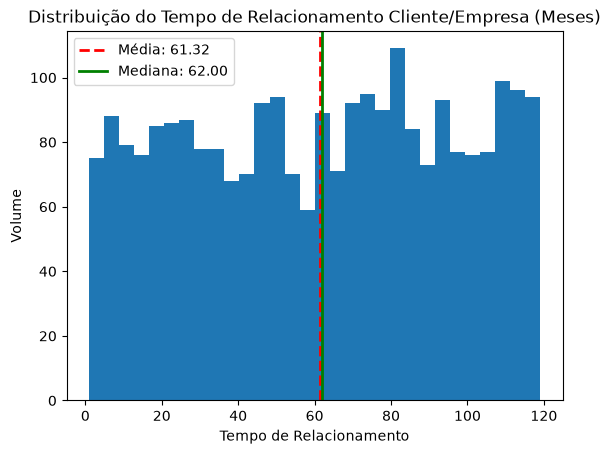

In [36]:
media = np.mean(df['tempo_relacionamento_cliente_empresa_meses'])
mediana = np.median(df['tempo_relacionamento_cliente_empresa_meses'])

plt.hist(df['tempo_relacionamento_cliente_empresa_meses'], bins=30)
plt.title('Distribuição do Tempo de Relacionamento Cliente/Empresa (Meses)')
plt.xlabel('Tempo de Relacionamento')
plt.ylabel('Volume')
plt.axvline(media, color='red', linewidth=2, linestyle='--', label=f'Média: {media:.2f}')
plt.axvline(mediana, color='green', linewidth=2, linestyle='-', label=f'Mediana: {mediana:.2f}')

plt.legend()
plt.show()

In [37]:
df['tempo_resolucao_problemas_dias'].value_counts()

tempo_resolucao_problemas_dias
3     237
2     229
8     227
11    214
7     213
0     208
4     206
9     204
10    197
6     197
1     192
5     176
Name: count, dtype: int64

In [38]:
df['tempo_relacionamento_cliente_empresa_meses'].min()

np.int64(1)

In [39]:
df['tempo_relacionamento_cliente_empresa_meses'].max()

np.int64(119)

In [40]:
df

,id_cliente,idade_cliente,regiao_cliente,tempo_relacionamento_cliente_empresa_meses,id_pedido,valor_pedido,quantidade_itens_pedido,desconto_aplicado_pedido,numero_parcelas_pagamento,tempo_total_entrega_dias,tempo_atraso_entrega_dias,valor_frete,numero_tentativas_entrega,numero_contatos_do_cliente_e_atendimento,tempo_resolucao_problemas_dias,pontuacao_nps,recompra_em_ate_30d,numero_reclamacoes_registradas_cliente,score_interno_satisfacao_cliente,classificacao_tempo_rel_cliente_empresa
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5,Longo
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0,Curto
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5,Longo
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3,Longo
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9,Longo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,2496,51,Sul,96,52496,615.81,6,11.41,2,14,3,28.96,2,1,2,3.7,0,3,4.3,Longo
2496,2497,37,Sul,89,52497,73.03,1,36.44,3,12,2,27.42,2,2,7,3.7,0,4,2.5,Longo
2497,2498,19,Sudeste,98,52498,522.78,1,4.84,9,2,2,38.94,1,1,1,7.4,0,3,6.2,Longo
2498,2499,41,Sul,51,52499,55.87,2,2.11,2,14,5,29.10,3,3,0,2.3,0,5,1.7,Longo


In [41]:
reclamacoes_registradas_clientes.groupby('classificacao_tempo_rel_cliente_empresa')['numero_reclamacoes_registradas_cliente'].sum()

classificacao_tempo_rel_cliente_empresa
Curto     248
Médio     788
Longo    9340
Name: numero_reclamacoes_registradas_cliente, dtype: int64

In [55]:
df['classificacao_tempo_rel_cliente_empresa'].value_counts()

classificacao_tempo_rel_cliente_empresa
Longo    2258
Médio     185
Curto      57
Name: count, dtype: int64

In [70]:
qtd_cliente_tempo_curto = len(df[df['classificacao_tempo_rel_cliente_empresa'] == 'Curto'])
qtd_cliente_tempo_medio = len(df[df['classificacao_tempo_rel_cliente_empresa'] == 'Médio'])
qtd_cliente_tempo_longo = len(df[df['classificacao_tempo_rel_cliente_empresa'] == 'Longo'])

In [71]:
porce_clientes_relacionamento_tempo_longo = (qtd_cliente_tempo_longo/quantidade_total_de_pedidos) * 100

print(f'Porcentagem de clientes supostamente fidelizados (mais de 12 meses): {porce_clientes_relacionamento_tempo_longo:.2f}%')

Porcentagem de clientes supostamente fidelizados (mais de 12 meses): 90.32%


In [61]:
qtd_cliente_tempo_longo

,id_cliente,idade_cliente,regiao_cliente,tempo_relacionamento_cliente_empresa_meses,id_pedido,valor_pedido,quantidade_itens_pedido,desconto_aplicado_pedido,numero_parcelas_pagamento,tempo_total_entrega_dias,tempo_atraso_entrega_dias,valor_frete,numero_tentativas_entrega,numero_contatos_do_cliente_e_atendimento,tempo_resolucao_problemas_dias,pontuacao_nps,recompra_em_ate_30d,numero_reclamacoes_registradas_cliente,score_interno_satisfacao_cliente,classificacao_tempo_rel_cliente_empresa
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5,Longo
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5,Longo
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3,Longo
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9,Longo
5,6,35,Sudeste,75,50006,568.76,6,36.58,3,4,5,41.82,2,2,3,0.9,0,5,1.5,Longo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,2496,51,Sul,96,52496,615.81,6,11.41,2,14,3,28.96,2,1,2,3.7,0,3,4.3,Longo
2496,2497,37,Sul,89,52497,73.03,1,36.44,3,12,2,27.42,2,2,7,3.7,0,4,2.5,Longo
2497,2498,19,Sudeste,98,52498,522.78,1,4.84,9,2,2,38.94,1,1,1,7.4,0,3,6.2,Longo
2498,2499,41,Sul,51,52499,55.87,2,2.11,2,14,5,29.10,3,3,0,2.3,0,5,1.7,Longo


In [ ]:
clientes_tempo_curto_reclamacoes = reclamacoes_registradas_clientes[reclamacoes_registradas_clientes['classificacao_tempo_rel_cliente_empresa'] == 'Curto']
num_clientes_tempo_curto = clientes_tempo_curto_reclamacoes['numero_reclamacoes_registradas_cliente'].sum()

clientes_tempo_medio_reclamacoes = reclamacoes_registradas_clientes[reclamacoes_registradas_clientes['classificacao_tempo_rel_cliente_empresa'] == 'Médio']
num_clientes_tempo_medio = clientes_tempo_medio_reclamacoes['numero_reclamacoes_registradas_cliente'].sum()

clientes_tempo_longo_reclamacoes = reclamacoes_registradas_clientes[reclamacoes_registradas_clientes['classificacao_tempo_rel_cliente_empresa'] == 'Longo']
num_clientes_tempo_longo = clientes_tempo_longo_reclamacoes['numero_reclamacoes_registradas_cliente'].sum()

In [43]:
num_reclamacoes_registradas_clientes = reclamacoes_registradas_clientes['numero_reclamacoes_registradas_cliente'].sum()

In [44]:
num_reclamacoes_registradas_clientes

np.int64(10376)

In [45]:
porcentagem_cliente_tempo_curto =  (num_clientes_tempo_curto/num_reclamacoes_registradas_clientes) * 100
porcentagem_cliente_tempo_medio = (num_clientes_tempo_medio/num_reclamacoes_registradas_clientes) * 100
porcentagem_cliente_tempo_longo = (num_clientes_tempo_longo/num_reclamacoes_registradas_clientes) * 100

print(f'Porcentagem de clientes que reclamaram e tem relacionamento de curto prazo com a empresa (até 3 meses): {porcentagem_cliente_tempo_curto:.2f}%)')
print(f'Porcentagem de clientes que reclamaram e tem relacionamento de médio prazo com a empresa (até 12 meses): {porcentagem_cliente_tempo_medio:.2f}%')
print(f'Porcentagem de clientes que reclamaram e tem relacionamento de longo prazo com a empresa(mais de 12 meses): {porcentagem_cliente_tempo_longo:.2f}%')

Porcentagem de clientes que reclamaram e tem relacionamento de curto prazo com a empresa (até 3 meses): 2.39%)
Porcentagem de clientes que reclamaram e tem relacionamento de médio prazo com a empresa (até 12 meses): 7.59%
Porcentagem de clientes que reclamaram e tem relacionamento de longo prazo com a empresa(mais de 12 meses): 90.02%


In [47]:
df['numero_contatos_do_cliente_e_atendimento'].value_counts()

numero_contatos_do_cliente_e_atendimento
1    816
2    640
0    554
3    314
4    132
5     34
6      7
7      3
Name: count, dtype: int64

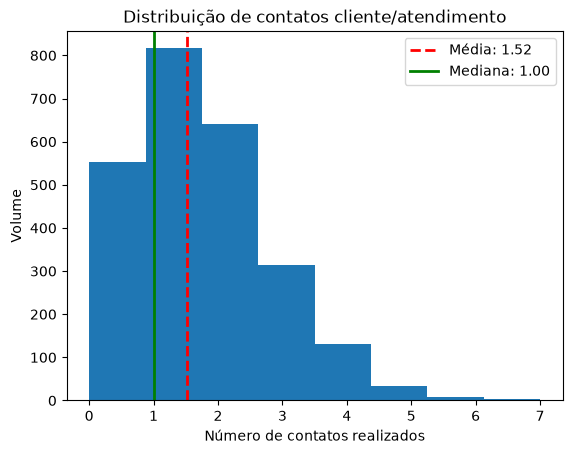

In [50]:
media = np.mean(df['numero_contatos_do_cliente_e_atendimento'])
mediana = np.median(df['numero_contatos_do_cliente_e_atendimento'])

plt.hist(df['numero_contatos_do_cliente_e_atendimento'], bins=8)
plt.title('Distribuição de contatos cliente/atendimento')
plt.xlabel('Número de contatos realizados')
plt.ylabel('Volume')
plt.axvline(media, color='red', linewidth=2, linestyle='--', label=f'Média: {media:.2f}')
plt.axvline(mediana, color='green', linewidth=2, linestyle='-', label=f'Mediana: {mediana:.2f}')

plt.legend()
plt.show()

In [54]:
contatos_cliente_maior_igual_2 = df[df['numero_contatos_do_cliente_e_atendimento'] >= 2]
qtd_contatos_clientes_maior_igual_2 = contatos_cliente_maior_igual_2.value_counts().sum()

porce_contatos_cliente_maior_igual_2 = (qtd_contatos_clientes_maior_igual_2 / quantidade_total_de_pedidos) * 100

print(f'Porcentagem de clientes que entraram em contato com o atendimento pelo menos 2 vezes: {porce_contatos_cliente_maior_igual_2}%')

Porcentagem de clientes que entraram em contato com o atendimento pelo menos 2 vezes: 45.2%
